In [161]:
import os
os.environ['KERAS_BACKEND'] = 'jax'
os.environ["PYTHONHASHSEED"] = "0"
import keras
keras.utils.set_random_seed(42) 
import tensorflow as tf

import pickle
import time
import bayesflow as bf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from constants import SHAPE_PRIOR_RANGES, FLASH_PAIRS, CUE, HAS_DEADLINE, BASE_PARAMS, MODEL_NAMES
from functions.prior import prior
from functions.likelihood import likelihood
from functions.samples_dict_to_array import samples_dict_to_array
from functions.resimulate_from_posterior import resimulate_from_posterior

In [162]:
simulator = bf.make_simulator([prior, likelihood])

sim_draws = simulator.sample(50)

In [163]:
par_keys = [
    "a_base",
    "v_scale",
    "t0"
]
par_names = [r"$a_\text{base}$", r"$v_\text{scale}$", r"$t_0$",]

In [164]:
# f = bf.diagnostics.plots.pairs_samples(
#     samples=sim_draws,
#     variable_keys=par_keys,
#     variable_names=par_names
# )

In [165]:
# 4 Parameter: v_scale, t0, a, lam
num_params = len(BASE_PARAMS) + len(SHAPE_PRIOR_RANGES[MODEL_NAMES[0]])

inference_network = bf.networks.CouplingFlow(
    num_params=num_params,
    num_coupling_layers=4,
    coupling_design="interleaved"
)

In [166]:
@keras.saving.register_keras_serializable()
def stack_trials_for_deepset(data, **kwargs):
    # if required keys are not present: return data as is
    # handle cases where data is already processed or in inverse mode
    if 'rt' not in data or 'choice' not in data or 'coherence' not in data:
        return data

    # stack rt, choice, and coherence along a new axis to create 2D array
    # Each row is one trial, and columns are features (rt, choice, coherence)
    stacked_data = tf.stack([data['rt'], data['choice'], data['coherence']], axis=-1)

    # new dictionary from input data
    # and adding 'summary_variables'
    output_data = {k: v for k, v in data.items() if k not in ['rt', 'choice', 'coherence']}
    output_data['summary_variables'] = stacked_data
    return output_data

adapter = (
    bf.adapters.Adapter()
    .to_array()
    .convert_dtype("float64", "float32")
    .concatenate(["v_scale", "t0", "a_base",*SHAPE_PRIOR_RANGES[MODEL_NAMES[0]]], into="inference_variables")
    .add_transform(stack_trials_for_deepset)
    .keep(["inference_variables", "summary_variables"])
)

In [167]:
 # coherence is present in the summary variables, so its going in the network.
sample = simulator.sample(batch_shape=(4,))
adapted = adapter(sample)
sv = adapted["summary_variables"]
print(sv.shape)                     
print(np.unique(sv[0, :, 2]))       

(4, 360, 3)
[0.1 0.2 0.3 0.4 0.5 0.6]


In [168]:

CHECKPOINT_DIR = os.path.join("models", "checkpoints", "ddm_sbi_run")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs("./models/networks", exist_ok=True) 

print(CHECKPOINT_DIR)

workflow = bf.BasicWorkflow(
    simulator=simulator,
    adapter=adapter,
    inference_network=inference_network,
    summary_network=bf.networks.SetTransformer(),
    checkpoint_filepath=CHECKPOINT_DIR,
    checkpoint_name=f"ddm_workflow_{MODEL_NAMES[0]}",
)


Existing checkpoints are not automatically loaded. Upon refitting, the checkpoints will be overwritten.
To load the stored approximator from the checkpoint, use approximator = keras.saving.load_model("models\checkpoints\ddm_sbi_run/ddm_workflow_exponential.keras")


models\checkpoints\ddm_sbi_run


In [169]:
# EPOCHS, BATCH_SIZE, NUM_BATCHES = 50, 32, 100
EPOCHS, BATCH_SIZE, NUM_BATCHES = 30, 32, 50
history_path = f"./models/networks/bayesflow_history_epoch_{EPOCHS}_{MODEL_NAMES[0]}.pkl"



In [170]:
## TRAINING THE MODEL
# commented out because of runtime

# history = workflow.fit_online(epochs=EPOCHS, batch_size=BATCH_SIZE, num_batches_per_epoch=NUM_BATCHES)

# tmp_path = history_path + ".tmp"
# with open(tmp_path, "wb") as f:
#     pickle.dump(history, f)
# os.replace(tmp_path, history_path)

print(f"History saved successfully to {history_path}!")
print(f"Model weights were checkpointed automatically to {CHECKPOINT_DIR}/")

print("!!! CHANGE name of ddm_workflow to incorporate model name")


History saved successfully to ./models/networks/bayesflow_history_epoch_30_exponential.pkl!
Model weights were checkpointed automatically to models\checkpoints\ddm_sbi_run/
!!! CHANGE name of ddm_workflow to incorporate model name


In [171]:
# load model with exponential decision boundary
history_path = f"./models/networks/bayesflow_history_epoch_{EPOCHS}_{MODEL_NAMES[0]}.pkl"
if os.path.exists(history_path) and os.path.getsize(history_path) > 0:
    with open(history_path, "rb") as f:
        history = pickle.load(f)
else:
    raise FileNotFoundError(
        f"{history_path} is missing or empty - re-run the training cell above "
        "before continuing."
    )


approximator = keras.saving.load_model(os.path.join(CHECKPOINT_DIR, f"ddm_workflow_{MODEL_NAMES[0]}.keras"))


## **Diagnostics**

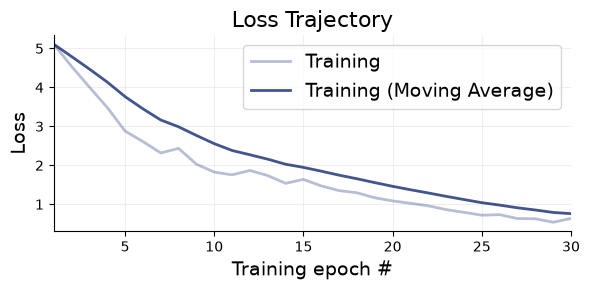

In [172]:
# Convergence
f  = bf.diagnostics.loss(history, figsize=(6,3))
f.savefig(f"images/diagnostics/loss_{MODEL_NAMES[0]}.pdf")

In [ ]:
# SB calibration
workflow.approximator = approximator

# recovery rates

num_samples = 1000
test_sims = workflow.simulate(400)
test_sims_params = {k: v for k, v in test_sims.items() if k in par_keys}
test_sims_data = {k: v for k, v in test_sims.items() if k not in par_keys}

samples = workflow.sample(conditions=test_sims_data, num_samples=num_samples)



In [ ]:
# settings for plots
label_map = {
    "v_scale": r"$v_{scale}$",
    "t0": r"$t_0$",
    "a_base": r"$a_{base}$",
    "lam": r"$\lambda$",
    "t_mid": r"$t_{\text{mid}}$",
    "k_sig": r"$k_\text{sig}$"
}

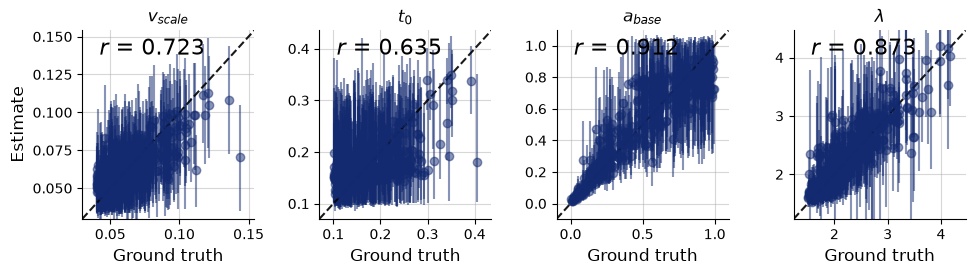

In [ ]:
f2 = bf.diagnostics.recovery(samples, test_sims, figsize = (10,3))

for ax in f2.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)

f2.savefig(f"images/diagnostics/recovery_{MODEL_NAMES[0]}.pdf", bbox_inches="tight")

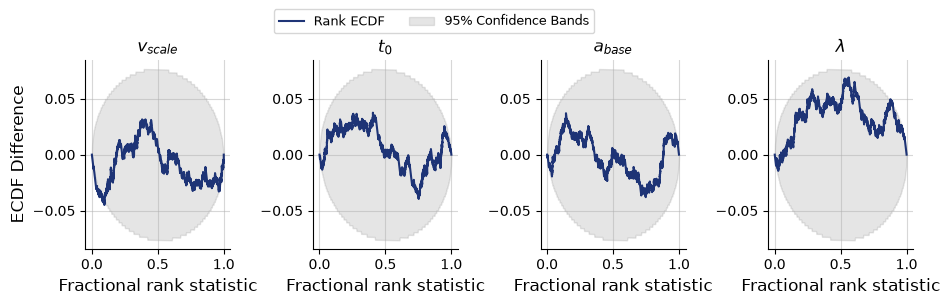

In [ ]:
f3 = bf.diagnostics.calibration_ecdf(samples, test_sims, figsize=(10, 3))
for ax in f3.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)

    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

# Eine gemeinsame Legende fürs gesamte Figure holen
handles, labels = f3.axes[0].get_legend_handles_labels()
f3.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=len(labels), fontsize=9)
f3.savefig(f"images/diagnostics/calibration_{MODEL_NAMES[0]}.pdf", bbox_inches="tight")

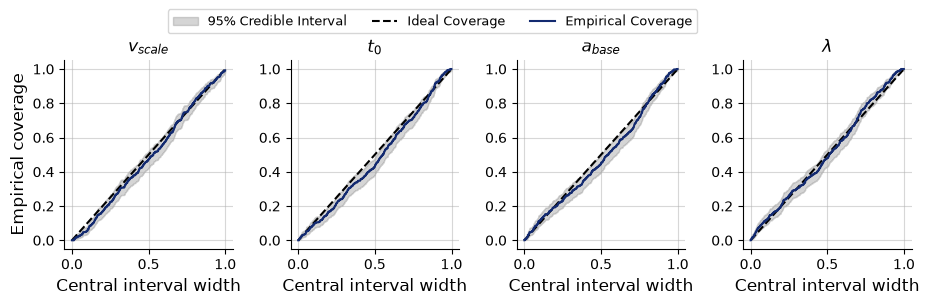

In [ ]:
f4 = bf.diagnostics.coverage(samples, test_sims, figsize=(10, 3))
for ax in f4.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

# Eine gemeinsame Legende fürs gesamte Figure holen
handles, labels = f4.axes[0].get_legend_handles_labels()
f4.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=len(labels), fontsize=9)
f4.savefig(f"images/diagnostics/coverage_{MODEL_NAMES[0]}.pdf", bbox_inches="tight")


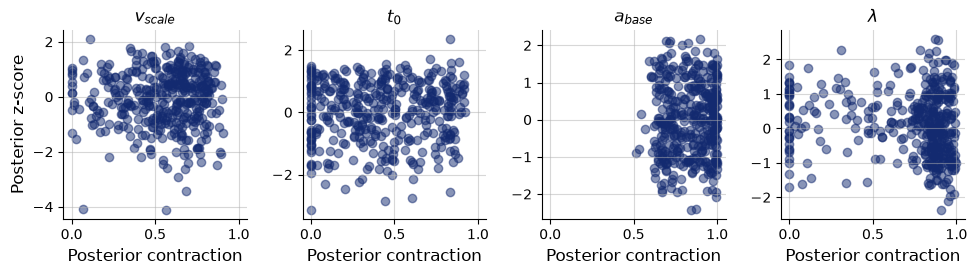

In [ ]:
f5 = bf.diagnostics.z_score_contraction(samples, test_sims, figsize=(10, 3))

for ax in f5.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)
f5.savefig(f"images/diagnostics/z_score_contraction_{MODEL_NAMES[0]}.pdf", bbox_inches="tight")


## **Inference**

In [ ]:
empirical_data = pd.read_csv("./data/Katsimposis/experiment-2-Flash.csv")

# mapping
mapping_diff = {
    "[0.55, 0.45]": 0.1,
    "[0.6, 0.4]": 0.2,
    "[0.65, 0.35]": 0.3,
    "[0.7, 0.3]": 0.4,
    "[0.75,0.25]": 0.5,
    "[0.8,0.2]": 0.6
}
empirical_data['difficulty'] = empirical_data["difficulty"].replace(mapping_diff)

mapping_deadline = {
    "Deadline": 1,
    "No Deadline": 0
}
empirical_data["has_deadline"] = empirical_data["deadline"].replace(mapping_deadline)
empirical_data["deadline"] = empirical_data["deadline"].replace(mapping_deadline)

mapping_cue = {
    "AC":1,
    "SP":0
}
empirical_data["cue"] = empirical_data["cue"].replace(mapping_cue)


empirical_data = empirical_data[
    (empirical_data["cue"] == CUE) & (empirical_data["deadline"] == HAS_DEADLINE)
].reset_index(drop=True)
# print(empirical_data.shape, empirical_data["difficulty"].unique())

In [ ]:
results = {}  # pp -> posterior samples

for pp_id, group in empirical_data.groupby("pp"):
    rt = group["rt"].to_numpy(dtype=np.float64)
    choice = group["acc"].to_numpy(dtype=np.float64)
    coherence = group["difficulty"].to_numpy(dtype=np.float64)
    cue = group["cue"].to_numpy(dtype=np.float64)
    deadline = group["has_deadline"].to_numpy(dtype=np.float64)

    if len(rt) < 10:
        continue

    data = {
        "rt": rt[np.newaxis, :],
        "choice": choice[np.newaxis, :],
        "coherence": coherence[np.newaxis, :],
        "cue": cue[np.newaxis, :],
        "has_deadline": deadline[np.newaxis, :],
    }

    # volle Posterior-Samples behalten, NICHT mitteln
    samples = approximator.sample(num_samples=1000, conditions=data)
    results[pp_id] = {
        "posterior": samples,   # für PPC-Simulation weiterverwenden
        "n_trials": len(rt),
        "empirical_rt": rt,
        "empirical_choice": choice,
        "coherence": coherence,
    }

Sampling: 100%|██████████| 1/1 [00:00<00:00,  4.02batch/s]


In [ ]:
from functions.get_param_order import get_param_order
def summarize_posterior(samples, model=None, ci=0.95):
    """
    samples: dict wie von approximator.sample() zurückgegeben,
             z.B. {"v_scale": array(1, n_draws), "t0": ..., ...}
    Gibt ein DataFrame mit einer Zeile pro Parameter zurück.
    """
    model = model or MODEL_NAMES[0]
    param_order = get_param_order(model)

    alpha = 1 - ci
    lower_q, upper_q = 100 * alpha / 2, 100 * (1 - alpha / 2)

    rows = []
    for p in param_order:
        draws = np.asarray(samples[p]).reshape(-1)
        rows.append({
            "param": p,
            "mean": draws.mean(),
            "median": np.median(draws),
            "sd": draws.std(),
            f"ci_{lower_q:.1f}": np.percentile(draws, lower_q),
            f"ci_{upper_q:.1f}": np.percentile(draws, upper_q),
        })
    return pd.DataFrame(rows)


def summarize_all_participants(results, model=None, ci=0.95):
    """
    results: dein Dict {pp_id: {"posterior": samples_dict, ...}}
    Gibt eine DataFrame mit einer Zeile pro (pp, param).
    """
    summaries = []
    for pp_id, res in results.items():
        df = summarize_posterior(res["posterior"], model=model, ci=ci)
        df.insert(0, "pp", pp_id)
        summaries.append(df)
    return pd.concat(summaries, ignore_index=True)

In [ ]:
print(type(results), len(results))
print(results)

<class 'dict'> 24


In [ ]:
os.makedirs("results", exist_ok=True)
summary_df = summarize_all_participants(results, model=MODEL_NAMES[0])
summary_df.to_csv(f"results/param_estimates_{MODEL_NAMES[0]}.csv", index=False)
summary_df

ValueError: No objects to concatenate

In [ ]:
def summary_to_latex_compact(summary_df, decimals=2, rename_map=None, resizebox=True):
    """
    Baut aus dem long-format summary_df (pp, param, mean, ci_low, ci_high)
    eine kompakte LaTeX-Tabelle von Hand, ohne pandas.to_latex()/jinja2.
    Parameter-Spaltentitel werden über rename_map (z.B. label_map) in
    LaTeX-Math-Notation umbenannt; die Tabelle wird optional per
    \resizebox auf \textwidth skaliert.
    """
    ci_cols = [c for c in summary_df.columns if c.startswith("ci_")]
    lower_col, upper_col = ci_cols[0], ci_cols[1]

    df = summary_df.copy()
    df["cell"] = df.apply(
        lambda r: f"{r['mean']:.{decimals}f} [{r[lower_col]:.{decimals}f}, {r[upper_col]:.{decimals}f}]",
        axis=1
    )

    caption=f"Posterior estimates for each participant for the {MODEL_NAMES[0]} decision boundary model."
    label = f"tab:posterior_estimates_{MODEL_NAMES[0]}"

    wide = df.pivot(index="pp", columns="param", values="cell").reset_index()
    wide = wide.rename(columns={"pp": "Participant"})

    if rename_map:
        # nur Parameter-Spalten umbenennen, "Participant" bleibt Text
        wide = wide.rename(columns=rename_map)

    n_cols = wide.shape[1]
    col_format = "l" + "c" * (n_cols - 1)
    header = " & ".join(str(c) for c in wide.columns) + r" \\"

    rows = []
    for _, row in wide.iterrows():
        rows.append(" & ".join(str(v) for v in row.values) + r" \\")

    tabular_lines = []
    tabular_lines.append(rf"\begin{{tabular}}{{{col_format}}}")
    tabular_lines.append(r"\toprule")
    tabular_lines.append(header)
    tabular_lines.append(r"\midrule")
    tabular_lines.extend(rows)
    tabular_lines.append(r"\bottomrule")
    tabular_lines.append(r"\end{tabular}")
    tabular_block = "\n".join(tabular_lines)

    if resizebox:
        tabular_block = (
            r"\resizebox{\textwidth}{!}{%" + "\n" +
            tabular_block + "\n" +
            r"}"
        )

    lines = []
    lines.append(r"\begin{table}")
    lines.append(r"\centering")
    lines.append(rf"\caption{{{caption}}}")
    lines.append(rf"\label{{{label}}}")
    lines.append(tabular_block)
    lines.append(r"\end{table}")

    return "\n".join(lines), wide

In [ ]:
latex_str, wide_df = summary_to_latex_compact(summary_df, decimals=2)
print(latex_str)

with open(f"results/param_estimates_{MODEL_NAMES[0]}.tex", "w") as f:
    f.write(latex_str)

\begin{table}
\centering
\caption{Posterior estimates for each participant for the exponential decision boundary model.}
\label{tab:posterior_estimates_exponential}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccc}
\toprule
Participant & a_base & lam & t0 & v_scale \\
\midrule
0 & 0.43 [0.11, 0.76] & 2.60 [1.31, 3.77] & 0.18 [0.06, 0.30] & 0.06 [0.03, 0.10] \\
1 & 0.24 [0.03, 0.43] & 2.69 [1.17, 4.15] & 0.17 [0.06, 0.28] & 0.06 [0.03, 0.10] \\
2 & 0.38 [0.07, 0.70] & 2.64 [1.42, 3.89] & 0.18 [0.06, 0.30] & 0.06 [0.03, 0.09] \\
3 & 0.06 [-0.03, 0.15] & 2.69 [0.87, 4.33] & 0.18 [0.07, 0.28] & 0.06 [0.03, 0.09] \\
4 & 0.03 [-0.07, 0.13] & 2.63 [1.00, 4.28] & 0.17 [0.08, 0.28] & 0.06 [0.03, 0.09] \\
5 & 0.21 [0.04, 0.37] & 2.65 [1.05, 4.22] & 0.17 [0.08, 0.27] & 0.06 [0.03, 0.10] \\
6 & 0.11 [-0.01, 0.23] & 2.75 [1.06, 4.47] & 0.18 [0.07, 0.27] & 0.06 [0.03, 0.09] \\
7 & 0.08 [-0.03, 0.19] & 2.72 [0.89, 4.36] & 0.17 [0.07, 0.28] & 0.06 [0.03, 0.09] \\
8 & 0.05 [-0.04, 0.13] & 2.71 [0.94, 

In [ ]:
def _plot_rt_distribution(ax, empirical_df, posterior_draws, model=None,
                           n_resim=100, seed=None, pp_label=""):
    """Draws empirical vs. simulated RT distribution (correct/error) into a given ax."""
    model = model or MODEL_NAMES[0]
    sims = resimulate_from_posterior(posterior_draws, model=model,
                                      n_resim=n_resim, seed=seed)

    rt_c_emp = empirical_df.loc[empirical_df["acc"] == 1, "rt"]
    rt_e_emp = empirical_df.loc[empirical_df["acc"] == 0, "rt"]
    ax.hist(rt_c_emp, bins=40, density=True, alpha=0.35, color="tab:blue", label="emp. correct")
    ax.hist(rt_e_emp, bins=40, density=True, alpha=0.35, color="tab:red", label="emp. error")

    sim_rt_c = np.concatenate([s["rt"][s["choice"] == 1] for s in sims])
    sim_rt_e = np.concatenate([s["rt"][s["choice"] == 0] for s in sims])
    ax.hist(sim_rt_c, bins=40, density=True, histtype="step", lw=2,
            color="tab:blue", linestyle="--", label="sim. correct")
    ax.hist(sim_rt_e, bins=40, density=True, histtype="step", lw=2,
            color="tab:red", linestyle="--", label="sim. error")

    ax.set_xlabel("RT (s)")
    ax.set_ylabel("Density")
    ax.set_title(pp_label)

In [ ]:
def plot_rt_distributions_grid(empirical_data, posterior_samples_per_pp,
                                model=None, n_resim=100, seed=None,
                                n_cols=6, space_legend=1.06, space_figure=0.93):
    model = model or MODEL_NAMES[0]
    pp_ids = list(posterior_samples_per_pp.keys())
    n_pp = len(pp_ids)
    n_rows = int(np.ceil(n_pp / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.8 * n_rows),
                              sharex=True, sharey=False)
    axes = np.atleast_2d(axes).reshape(n_rows, n_cols)

    for i, pp_id in enumerate(pp_ids):
        ax = axes[i // n_cols, i % n_cols]
        emp = empirical_data[empirical_data["pp"] == pp_id]
        draws = samples_dict_to_array(posterior_samples_per_pp[pp_id], model=model)
        _plot_rt_distribution(ax, emp, draws, model=model, n_resim=n_resim,
                               seed=seed, pp_label=f"Participant {pp_id}")

    # leere Subplots ausblenden, falls n_pp nicht exakt n_rows*n_cols füllt
    for j in range(n_pp, n_rows * n_cols):
        axes[j // n_cols, j % n_cols].axis("off")

    # eine gemeinsame Legende statt 24x dieselbe
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, fontsize=12,
            bbox_to_anchor=(0.5, space_legend))

    plt.tight_layout(rect=[0, 0, 1, space_figure])
    return fig

In [ ]:
fig = plot_rt_distributions_grid(empirical_data, {pp_id: res["posterior"] for pp_id, res in results.items()}, 
n_cols = 4, space_legend = 1, space_figure = 0.98, model = MODEL_NAMES[0])
plt.show()
fig.savefig(f"images/ppc_{MODEL_NAMES[0]}_all.pdf", bbox_inches="tight")

ValueError: Number of rows must be a positive integer, not 0

In [ ]:
selected = {2: results[2]["posterior"], 7: results[7]["posterior"]}

fig = plot_rt_distributions_grid(empirical_data, selected, n_cols=2)
plt.show()
fig.savefig(f"images/ppc_{MODEL_NAMES[0]}_participant_2_7.pdf", bbox_inches="tight")

KeyError: 2

In [ ]:
resim_datasets = resimulate_from_posterior(all_samples, model="exponential", n_resim=100)

NameError: name 'all_samples' is not defined

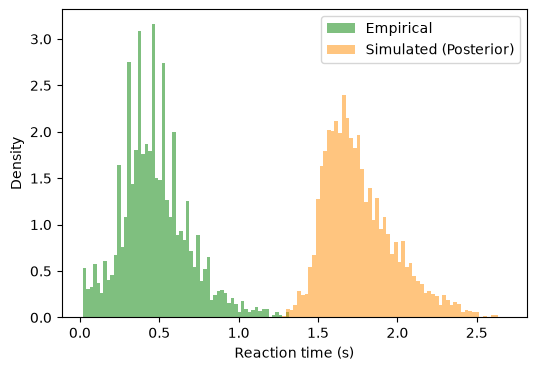

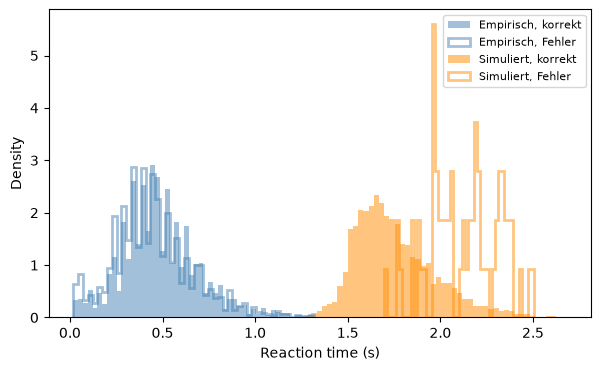

Empirische Accuracy: 0.6298157453936348
Simulierte Accuracy (Posterior-Mittel): 0.9845938


In [ ]:
if len(resim_datasets) > 0:
    # 1. Alle Resim-RTs/Choices/Accuracy zusammenführen (nur gültige Antworten, choice != -1)
    resim_rt_all = np.concatenate([d["rt"][d["choice"] != -1] for d in resim_datasets])
    resim_choice_all = np.concatenate([d["choice"][d["choice"] != -1] for d in resim_datasets])

    # 2. Empirische Daten (bereits gefiltert auf CUE=0, HAS_DEADLINE=1)
    emp_rt = df["rt"].to_numpy(dtype=np.float64)
    emp_choice = df["acc"].to_numpy(dtype=np.float64)
    valid_emp = ~np.isnan(emp_choice)
    emp_rt, emp_choice = emp_rt[valid_emp], emp_choice[valid_emp]

    # 3a. RT-Verteilung insgesamt
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(emp_rt, bins=60, density=True, alpha=0.5, label="Empirical", color="green")
    ax.hist(resim_rt_all, bins=60, density=True, alpha=0.5, label="Simulated (Posterior)", color="darkorange")
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend()
    plt.show()

    # 3b. Getrennt nach korrekt/inkorrekt (Slow-Errors-Signatur etc.)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(emp_rt[emp_choice == 1], bins=50, density=True, alpha=0.5, label="Empirisch, korrekt", color="steelblue")
    ax.hist(emp_rt[emp_choice == 0], bins=50, density=True, alpha=0.5, label="Empirisch, Fehler", color="steelblue", histtype="step", linewidth=2)
    ax.hist(resim_rt_all[resim_choice_all == 1], bins=50, density=True, alpha=0.5, label="Simuliert, korrekt", color="darkorange")
    ax.hist(resim_rt_all[resim_choice_all == 0], bins=50, density=True, alpha=0.5, label="Simuliert, Fehler", color="darkorange", histtype="step", linewidth=2)
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend(fontsize=8)
    plt.show()

    # 3c. Accuracy insgesamt (Anteil choice==1) empirisch vs. simuliert
    print("Empirische Accuracy:", emp_choice.mean())
    print("Simulierte Accuracy (Posterior-Mittel):", resim_choice_all.mean())

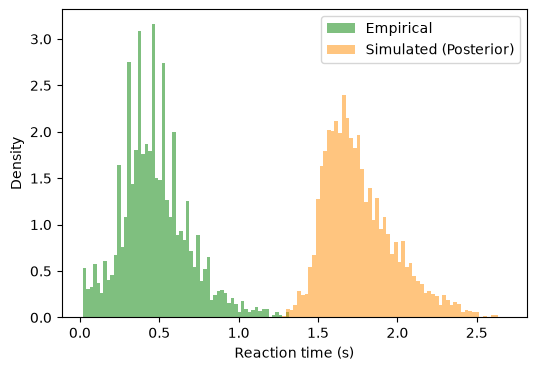

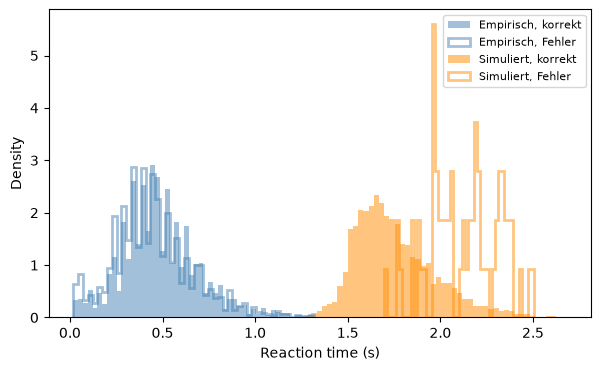

Empirische Accuracy: 0.6298157453936348
Simulierte Accuracy (Posterior-Mittel): 0.9845938


In [ ]:
if len(resim_datasets) > 0:
    # 1. Alle Resim-RTs/Choices/Accuracy zusammenführen (nur gültige Antworten, choice != -1)
    resim_rt_all = np.concatenate([d["rt"][d["choice"] != -1] for d in resim_datasets])
    resim_choice_all = np.concatenate([d["choice"][d["choice"] != -1] for d in resim_datasets])

    # 2. Empirische Daten (bereits gefiltert auf CUE=0, HAS_DEADLINE=1)
    emp_rt = df["rt"].to_numpy(dtype=np.float64)
    emp_choice = df["acc"].to_numpy(dtype=np.float64)
    valid_emp = ~np.isnan(emp_choice)
    emp_rt, emp_choice = emp_rt[valid_emp], emp_choice[valid_emp]

    # 3a. RT-Verteilung insgesamt
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(emp_rt, bins=60, density=True, alpha=0.5, label="Empirical", color="green")
    ax.hist(resim_rt_all, bins=60, density=True, alpha=0.5, label="Simulated (Posterior)", color="darkorange")
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend()
    plt.show()

    # 3b. Getrennt nach korrekt/inkorrekt (Slow-Errors-Signatur etc.)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(emp_rt[emp_choice == 1], bins=50, density=True, alpha=0.5, label="Empirisch, korrekt", color="steelblue")
    ax.hist(emp_rt[emp_choice == 0], bins=50, density=True, alpha=0.5, label="Empirisch, Fehler", color="steelblue", histtype="step", linewidth=2)
    ax.hist(resim_rt_all[resim_choice_all == 1], bins=50, density=True, alpha=0.5, label="Simuliert, korrekt", color="darkorange")
    ax.hist(resim_rt_all[resim_choice_all == 0], bins=50, density=True, alpha=0.5, label="Simuliert, Fehler", color="darkorange", histtype="step", linewidth=2)
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend(fontsize=8)
    plt.show()

    # 3c. Accuracy insgesamt (Anteil choice==1) empirisch vs. simuliert
    print("Empirische Accuracy:", emp_choice.mean())
    print("Simulierte Accuracy (Posterior-Mittel):", resim_choice_all.mean())